In [1]:
import os
import xarray as xr
import numpy as np
from glob import glob
from datetime import datetime
import argparse
from pathlib import Path
import subprocess

In [2]:
# Load regridded model forecast data
year = 2019
ds = xr.open_dataset(f'/glade/derecho/scratch/rajatm/s2s_model/test_regrid/merged_precip_{year}.nc') 

In [3]:
# Load IMD (ground truth) data
imd_file = f"/glade/derecho/scratch/rajatm/monsoon_onset_eval_data/IMD_2by2/data_{year}.nc"
imd_ds = xr.open_dataset(imd_file)

print("IMD dataset variables:", list(imd_ds.data_vars.keys()))
print("IMD dataset dimensions:", dict(imd_ds.dims))
print("IMD dataset coordinates:", list(imd_ds.coords.keys()))

# Check the structure of IMD data
print("\nIMD data structure:")
print(imd_ds)

IMD dataset variables: ['RAINFALL']
IMD dataset dimensions: {'TIME': 365, 'latitude': 16, 'longitude': 17}
IMD dataset coordinates: ['TIME', 'longitude', 'latitude']

IMD data structure:
<xarray.Dataset> Size: 797kB
Dimensions:    (TIME: 365, latitude: 16, longitude: 17)
Coordinates:
  * TIME       (TIME) datetime64[ns] 3kB 2019-01-01 2019-01-02 ... 2019-12-31
  * longitude  (longitude) int64 136B 68 70 72 74 76 78 ... 90 92 94 96 98 100
  * latitude   (latitude) int64 128B 8 10 12 14 16 18 20 ... 28 30 32 34 36 38
Data variables:
    RAINFALL   (TIME, latitude, longitude) float64 794kB ...
Attributes:
    regrid_method:  conservative


/glade/derecho/scratch/rajatm/tmp/ipykernel_27187/3396547673.py:6: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  print("IMD dataset dimensions:", dict(imd_ds.dims))


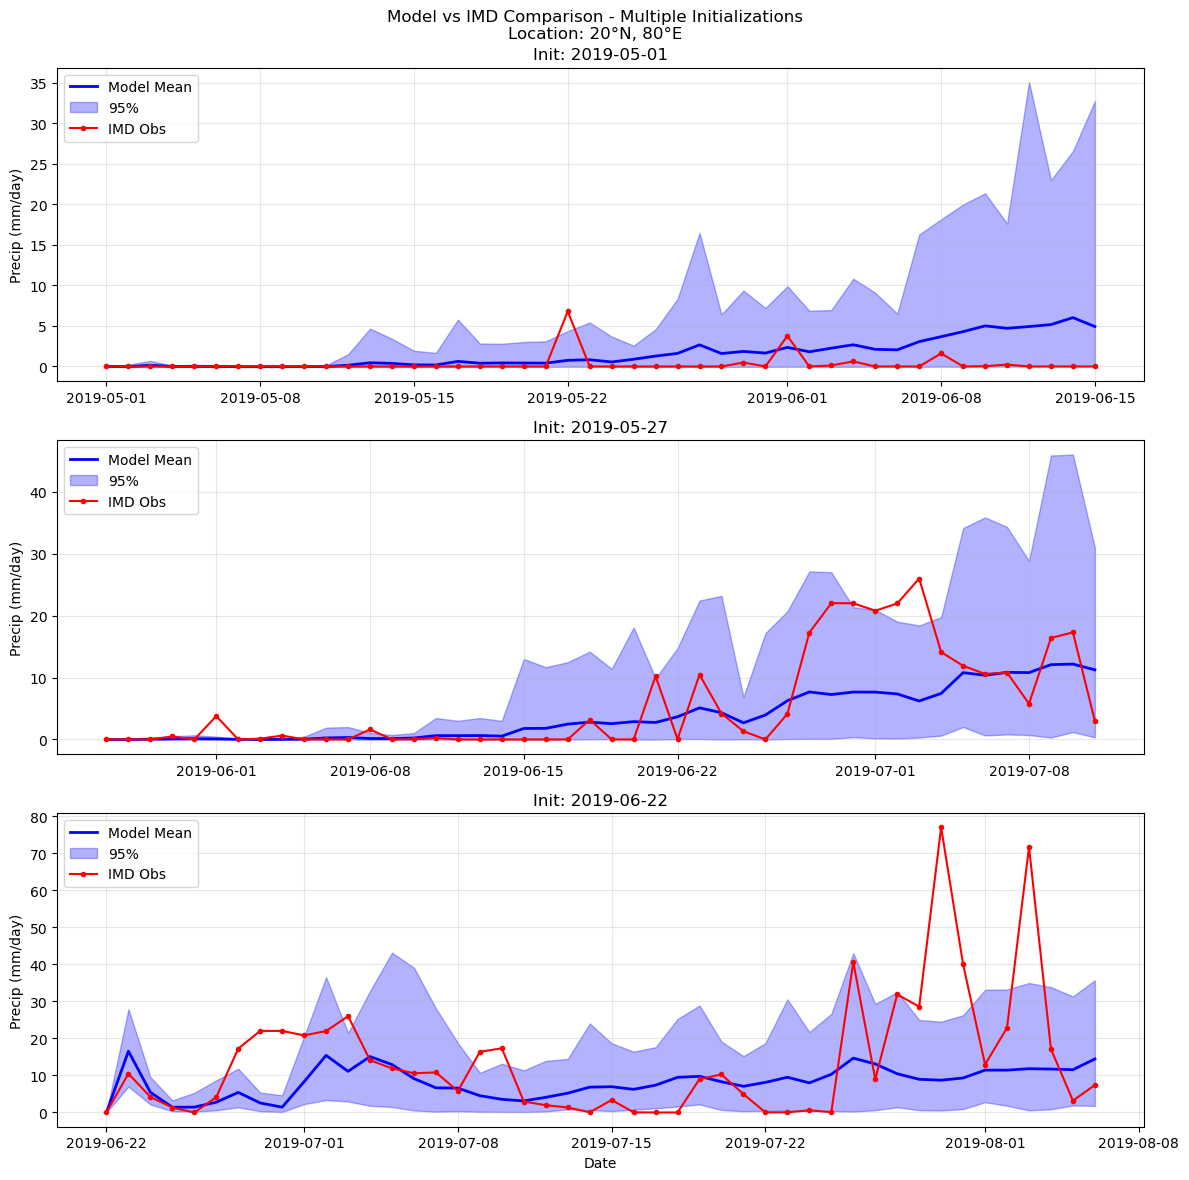

In [5]:
import matplotlib.pyplot as plt
import pandas as pd
# Updated function for multiple initialization comparisons
def compare_model_imd_multiple_inits(ds, imd_ds, lat_sel=20, lon_sel=80, n_inits=3):
    """
    Compare model forecasts with IMD observations for multiple initialization times
    """
    
    fig, axes = plt.subplots(n_inits, 1, figsize=(12, 4*n_inits))
    if n_inits == 1:
        axes = [axes]
    
    ds_stats = ds["total_precipitation_24hr"] * 1000
    
    for i in range(n_inits):
        init_idx = i * (len(ds.init_time) // n_inits)  # Spread out init times
        
        # Model data
        selected_model = ds_stats.isel(init_time=init_idx).sel(lat=lat_sel, lon=lon_sel, method='nearest')
        ensemble_mean = selected_model.mean(dim='member')
        p2_5 = selected_model.quantile(0.025, dim='member')
        p97_5 = selected_model.quantile(0.975, dim='member')
        
        # Get dates
        init_date = pd.to_datetime(ds.init_time[init_idx].values)
        forecast_dates = pd.date_range(start=init_date, periods=len(ensemble_mean), freq='D')
        
        # IMD data (note: using 'RAINFALL', 'TIME', 'latitude', 'longitude')
        imd_selected = imd_ds['RAINFALL'].sel(latitude=lat_sel, longitude=lon_sel, method='nearest')
        imd_period = imd_selected.sel(TIME=slice(init_date, forecast_dates[-1]))
        
        # Plot
        axes[i].plot(forecast_dates, ensemble_mean.values, 
                    'b-', label='Model Mean', linewidth=2)
        axes[i].fill_between(forecast_dates, p2_5.values, p97_5.values,
                           alpha=0.3, color='blue', label='95%')
        
        if len(imd_period.TIME) > 0:
            axes[i].plot(imd_period.TIME, imd_period.values, 
                        'ro-', label='IMD Obs', markersize=3)
        
        axes[i].set_title(f'Init: {init_date.strftime("%Y-%m-%d")}')
        axes[i].set_ylabel('Precip (mm/day)')
        axes[i].legend()
        axes[i].grid(True, alpha=0.3)
        
        if i == n_inits - 1:
            axes[i].set_xlabel('Date')
    
    plt.suptitle(f'Model vs IMD Comparison - Multiple Initializations\n'
                f'Location: {lat_sel}°N, {lon_sel}°E')
    plt.tight_layout()
    plt.show()

# Run the comparison
compare_model_imd_multiple_inits(ds, imd_ds, lat_sel=20, lon_sel=80, n_inits=3)